## Output Comparison
Compare output across sites

In [1]:
# Run settings
sites = ['Tony Grove RS','Tony Grove RS']
namelists = ['gbc','ghelaps']
forcing_strs = ['01011010','01011010']
forcing_versions = ['0.10.1','0.10.1']
versions = ['0005','0008']
isAlpine = True

In [2]:
# Load environmental variables if on Alpine, otherwise they should be stored
import os

# Configure environmental variables
if isAlpine:
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output/' #Alpine
    os.environ['SNOTEL_PATH'] = r'/pl/active/snotelmodelling/snotel/'
    os.environ['FORCING_PATH'] = r'/pl/active/snotelmodelling/model_data/input/forcing/'

In [3]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 
from buildforcing.datasets import PNNLSnotel

Load datasets

In [ ]:
forcing = LM4Forcing(site=sites[0], forcing_string=forcing_strs[0], version=forcing_versions[0], spinup=False)
forcing_vars = forcing.get_variables()
forcing_vars.head()

In [4]:
models = {}
for (site,namelist,forcing_str,version) in zip(sites,namelists,forcing_strs,versions):
    name = '_'.join((site.lower().replace(' ',''),forcing_str,namelist,version)) 
    models[name] = LM4ModelOutput(site=site, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)

In [ ]:
models

In [ ]:
daily_vars = models[0].get_variables(diag='land_daily')

In [ ]:
monthly_vars = model.get_variables(diag='land_month')

In [5]:
snotel = PNNLSnotel(sites[0], os.environ['SNOTEL_PATH'])
snotel.load_data()
snotel_data = snotel.data

# Remove timezone from index
snotel_data.index = snotel_data.index.tz_localize(None)
snotel_data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
2009-06-08,NaN,NaN,NaN,NaN,0.0
2009-06-09,NaN,NaN,NaN,NaN,0.0
2009-06-10,12.261111,5.394444,8.255556,NaN,0.0
2009-06-11,13.405556,5.394444,8.255556,NaN,0.0
2009-06-12,17.411111,4.822222,10.544444,NaN,0.0


### Snow

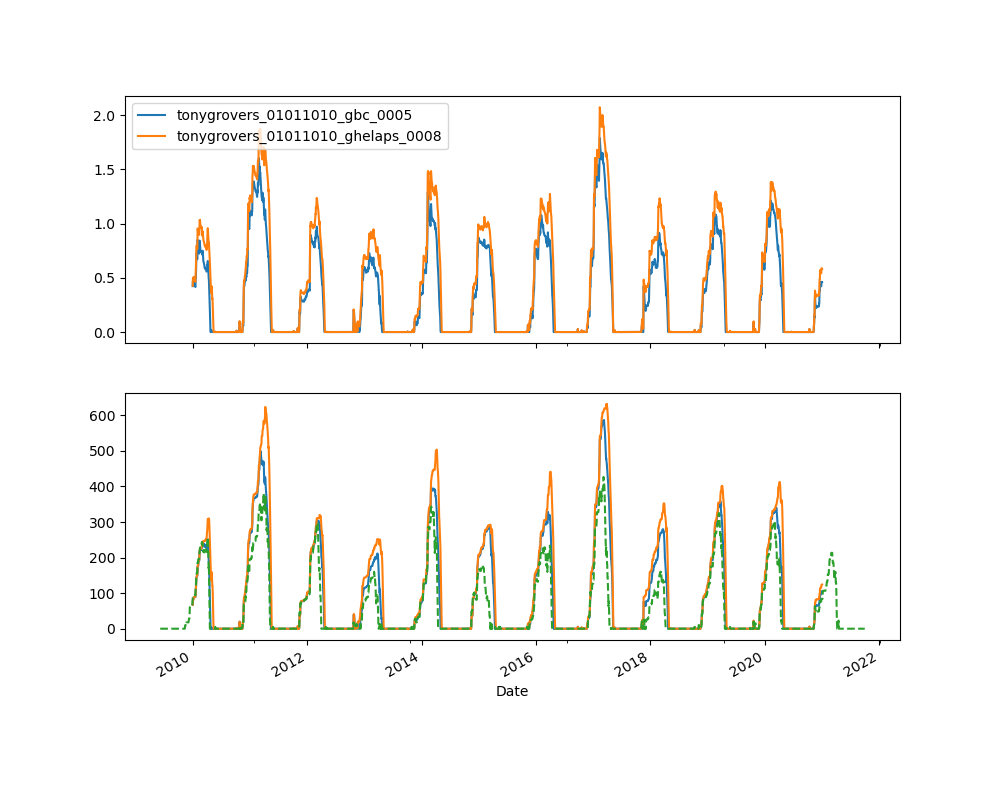

In [6]:
# Plot snow
fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

for output in models:
    model_snow = models[output].get_data(['snow','snow_depth'],'land_daily')
    model_snow['snow_depth'].plot(ax=ax[0], label=output)
    model_snow['snow'].plot(ax=ax[1], label=output)

# Add on SNOTEL
snotel_data['swe_mm'].plot(ax=ax[1], label='SNOTEL', style='--')
    
ax[0].legend()


In [ ]:
# Plot just showing SWE comparison for 10 years, use in presentations
fig, ax = plt.subplots(figsize=(12, 6))
snotel_data.loc['2005':'2015', 'swe_mm'].plot(ax=ax, label='SNOTEL SWE', color='blue')
model_snow['snow'].loc['2005':'2015'].plot(ax=ax, label='Model SWE', color='red', alpha=0.5)
plt.title(f'SWE Comparison at {site} (2005-2015)', fontsize=16)
ax.set_ylabel('SWE (mm)')
ax.legend()

#### RMSE Calculation

In [ ]:
# Shift snotel data index by 12 hours to match model output timing
snotel_data.index = snotel_data.index + pd.Timedelta(hours=12)

In [ ]:
# Combine model and snotel data
combined_df = pd.merge(model_snow, snotel_data[['swe_mm']], left_index=True, right_index=True, how='inner')

In [ ]:
# Calculate the difference between model and snotel SWE
combined_df['swe_diff'] = combined_df['snow'] - combined_df['swe_mm']

In [ ]:
# Calculate the RMSE, don't use first year of data to avoid spinup effects
combined_df = combined_df[combined_df.index >= (combined_df.index.min() + pd.DateOffset(years=1))]
rmse = (combined_df['swe_diff']**2).mean()**0.5
print(f'RMSE between model and SNOTEL SWE: {rmse:.2f} mm')

In [ ]:
# nRMSE
nrmse = rmse / combined_df['swe_mm'].mean()
print(f'mean SNOTEL SWE: {combined_df["swe_mm"].mean():.2f} mm')
print(f'nRMSE = {nrmse}')

### Snow Days Calc

In [ ]:
test = combined_df.loc['2015-10':'2016-07',['snow','swe_mm']]
print(f'SNOTEL: {test.loc[test['swe_mm'] > 5, 'swe_mm'].count()}')
print(f'Model: {test.loc[test['snow'] > 5, 'snow'].count()}')

In [ ]:
#Whole dataset
print(f'SNOTEL: {combined_df.loc[combined_df['swe_mm'] > 5, 'swe_mm'].count()}')
print(f'Model: {combined_df.loc[combined_df['snow'] > 5, 'snow'].count()}')